In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (precision_score, recall_score, f1_score,
                             accuracy_score, confusion_matrix)

df = pd.read_csv("churn_fintech_sample.csv")
X = df.drop(columns=['id_nasabah', 'kota', 'churn'])
y = df["churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)



In [2]:
model = make_pipeline(StandardScaler(),
                      LogisticRegression(class_weight="balanced", max_iter=1000))


cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
skor_dev = cross_val_predict(model, X_train, y_train, cv=cv, method="predict_proba")[:, 1]


model.fit(X_train, y_train)
skor_test = model.predict_proba(X_test)[:, 1]




In [3]:
thershold = np.round(np.arange(0.05, 0.96, 0.05), 2)
baris = []
for t in thershold:
    d = skor_dev >= t
    baris.append({
        "threshold": t,
        "churn": int(d.sum()),
        "recall": recall_score(y_train, d),
        "precision": precision_score(y_train, d, zero_division=0),
        "f1": f1_score(y_train, d, zero_division=0),
    })
tabel = pd.DataFrame(baris)
tabel.round(3)

,threshold,churn,recall,precision,f1
0,0.05,6804,0.998,0.080,0.148
1,0.10,6383,0.994,0.085,0.156
2,0.15,5908,0.980,0.090,0.166
3,0.20,5322,0.954,0.098,0.177
4,0.25,4760,0.928,0.106,0.191
5,0.30,4217,0.890,0.115,0.204
6,0.35,3704,0.864,0.127,0.222
7,0.40,3147,0.815,0.141,0.241
8,0.45,2697,0.761,0.154,0.256
9,0.50,2260,0.701,0.169,0.272


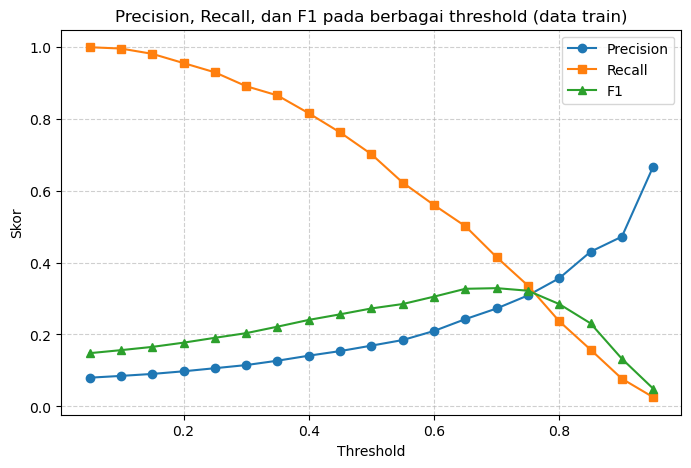

In [4]:
plt.figure(figsize=(8, 5))
plt.plot(tabel["threshold"], tabel["precision"], marker="o", label="Precision")
plt.plot(tabel["threshold"], tabel["recall"], marker="s", label="Recall")
plt.plot(tabel["threshold"], tabel["f1"], marker="^", label="F1")
plt.xlabel("Threshold")
plt.ylabel("Skor")
plt.title("Precision, Recall, dan F1 pada berbagai threshold (data train)")
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()
plt.show()

In [5]:
# TESTING DATA

BIAYA_PESAN      = 5_000
NILAI_NASABAH    = 150_000
PELUANG_BERHASIL = 0.30

def keuntungan(y_asli, skor, t):
    ditandai = skor >= t
    tp = (ditandai & (y_asli.values == 1)).sum()
    return tp * PELUANG_BERHASIL * NILAI_NASABAH - ditandai.sum() * BIAYA_PESAN

grid = np.round(np.arange(0.05, 0.96, 0.01), 2)
untung_dev = [keuntungan(y_train, skor_dev, t) for t in grid]
THRESHOLD = grid[int(np.argmax(untung_dev))]
print("Threshold terbaik:", THRESHOLD)

churn = skor_test >= THRESHOLD
tn, fp, fn, tp = confusion_matrix(y_test, churn).ravel()

print("Churn terdeteksi (TP):", tp)
print("Salah kira (FP):", fp)
print("Churn tidak terdeteksi (FN):", fn)
print("Bertahan dan benar (TN):", tn)
print()
print("Akurasi  :", round(accuracy_score(y_test, churn), 3))
print("Precision:", round(precision_score(y_test, churn), 3))
print("Recall   :", round(recall_score(y_test, churn), 3))
print()
print("Keuntungan di test (Rp):", int(keuntungan(y_test, skor_test, THRESHOLD)))
print("Keuntungan jika threshold 0.5 (Rp):", int(keuntungan(y_test, skor_test, 0.5)))

Threshold terbaik: 0.64
Churn terdeteksi (TP): 119
Salah kira (FP): 400
Churn tidak terdeteksi (FN): 115
Bertahan dan benar (TN): 2366

Akurasi  : 0.828
Precision: 0.229
Recall   : 0.509

Keuntungan di test (Rp): 2759999
Keuntungan jika threshold 0.5 (Rp): 2484999
